# Import packages

In [1]:
# import all packages
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import pandas as pd
import numpy as np
import datetime as dt
from datetime import UTC, datetime
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import missingno as msno
import seaborn as sns
from scipy import stats
from mlxtend.frequent_patterns import apriori

os.getcwd()

'D:\\MySkill\\Python for Data Analysis\\repo\\MySkill-Data-Science-and-Analysis'

# Import data from CSV to DataFrame

In [2]:
df = pd.read_csv('./online_retail_II.xlsx.csv', header=0, encoding='latin1')
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,09-12-2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,09-12-2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,09-12-2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,09-12-2011 12:50,4.95,12680.0,France


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


# Data Cleaning

In [4]:
df_clean = df.copy()
# convert PurchaseDate column to modern timezone-aware UTC datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='%d-%m-%Y %H:%M', utc=True)

In [5]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype              
---  ------       --------------   -----              
 0   Invoice      541910 non-null  str                
 1   StockCode    541910 non-null  str                
 2   Description  540456 non-null  str                
 3   Quantity     541910 non-null  int64              
 4   InvoiceDate  541910 non-null  datetime64[us, UTC]
 5   Price        541910 non-null  float64            
 6   Customer ID  406830 non-null  float64            
 7   Country      541910 non-null  str                
dtypes: datetime64[us, UTC](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [6]:
# make year_month column
df_clean['year_month'] = df_clean['InvoiceDate'].dt.to_period('M')

In [7]:
# check null data
df_clean.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
year_month          0
dtype: int64

## Handling Description null data

In [8]:
# make StockCode mapping to Description
product_dict = (
    df_clean.dropna(subset=["Description"])
    .set_index("StockCode")["Description"]
    .to_dict()
)

# fill null Description
df_clean["Description"] = df_clean["Description"].fillna(df["StockCode"].map(product_dict))

# delete the rest of null data at Description
df_clean = df_clean.dropna(subset=["Description"])

## Handling Customer ID null data

In [9]:
# calculate null data percentage
print((df_clean.isnull().sum() / len(df)) * 100)

Invoice         0.000000
StockCode       0.000000
Description     0.000000
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    24.905981
Country         0.000000
year_month      0.000000
dtype: float64


<Figure size 1000x600 with 0 Axes>

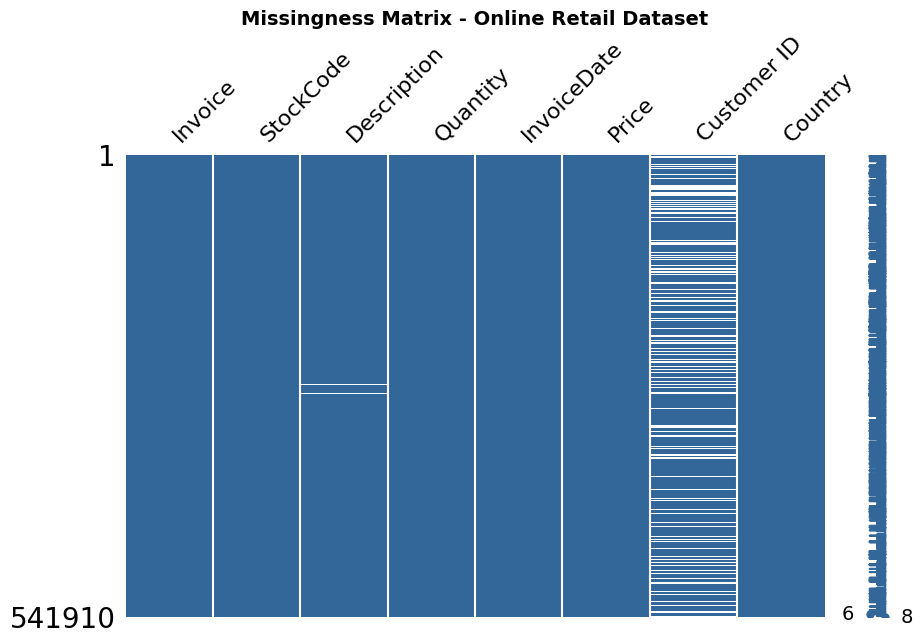

<Figure size 800x600 with 0 Axes>

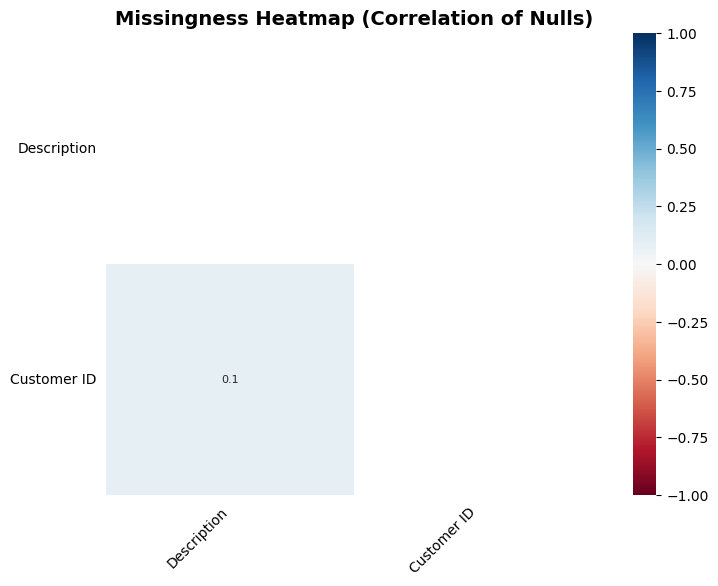

In [10]:
# Matrix visualize the null position
plt.figure(figsize=(10, 6))
msno.matrix(df, figsize=(10, 6), color=(0.2, 0.4, 0.6))
plt.title(
    "Missingness Matrix - Online Retail Dataset", fontsize=14, fontweight="bold"
)
plt.show()

# Heatmap to check if null column corelated to other null column
plt.figure(figsize=(8, 6))
msno.heatmap(df, figsize=(8, 6), fontsize=10)
plt.title(
    "Missingness Heatmap (Correlation of Nulls)", fontsize=14, fontweight="bold"
)
plt.show()

In [11]:
# Make a biner column converter for Customer ID, 1 for null, 0 for non-null
df_clean["CustomerID_missing"] = df_clean["Customer ID"].isnull().astype(int)

# Make sure if the null data corelated with 'Country' column
print(
    df_clean.groupby("Country")["CustomerID_missing"]
    .mean()
    .sort_values(ascending=False)
)

Country
Hong Kong               1.000000
Unspecified             0.452915
United Kingdom          0.269473
Israel                  0.158249
Bahrain                 0.105263
EIRE                    0.086750
Switzerland             0.062438
Portugal                0.025675
France                  0.007712
Canada                  0.000000
Australia               0.000000
Brazil                  0.000000
Belgium                 0.000000
Austria                 0.000000
Finland                 0.000000
European Community      0.000000
Greece                  0.000000
Germany                 0.000000
Denmark                 0.000000
Czech Republic          0.000000
Channel Islands         0.000000
Cyprus                  0.000000
Lebanon                 0.000000
Japan                   0.000000
Italy                   0.000000
Iceland                 0.000000
Norway                  0.000000
Lithuania               0.000000
Netherlands             0.000000
Malta                   0.000000
Sa

In [12]:
df_clean.isnull().sum()

Invoice                    0
StockCode                  0
Description                0
Quantity                   0
InvoiceDate                0
Price                      0
Customer ID           134968
Country                    0
year_month                 0
CustomerID_missing         0
dtype: int64

## Delete Negative Quantity

In [13]:
df_clean['Quantity'].astype(int)

0         6
1         6
2         8
3         6
4         6
         ..
541905    6
541906    4
541907    4
541908    3
541909    1
Name: Quantity, Length: 541798, dtype: int64

In [14]:
# Show Quantity less than 0 where is represent cancelled
print(df_clean.loc[df['Quantity'] < 0, ['Description', 'Quantity']])

                             Description  Quantity
141                             Discount        -1
154      SET OF 3 COLOURED  FLYING DUCKS        -1
235       PLASTERS IN TIN CIRCUS PARADE        -12
236     PACK OF 12 PINK PAISLEY TISSUES        -24
237     PACK OF 12 BLUE PAISLEY TISSUES        -24
...                                  ...       ...
540449   ZINC T-LIGHT HOLDER STARS SMALL       -11
541541                            Manual        -1
541715        VICTORIAN SEWING BOX LARGE        -5
541716  HANGING HEART JAR T-LIGHT HOLDER        -1
541717     36 PENCILS TUBE RED RETROSPOT        -5

[10527 rows x 2 columns]


In [15]:
df_clean = df_clean[df_clean['Quantity'] > 0].copy()

In [16]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00+00:00,2.55,17850.0,United Kingdom,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00+00:00,2.75,17850.0,United Kingdom,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0


## Delete outlier

In [17]:
# Delete outlier
df_clean = df_clean[(np.abs(stats.zscore(df_clean[['Price']]))<3).all(axis=1)]
df_clean = df_clean.reset_index(drop=True)
df_clean

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00+00:00,2.55,17850.0,United Kingdom,2010-12,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00+00:00,2.75,17850.0,United Kingdom,2010-12,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00+00:00,3.39,17850.0,United Kingdom,2010-12,0
...,...,...,...,...,...,...,...,...,...,...
530585,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00+00:00,2.10,12680.0,France,2011-12,0
530586,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00+00:00,4.15,12680.0,France,2011-12,0
530587,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00+00:00,4.15,12680.0,France,2011-12,0
530588,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00+00:00,4.95,12680.0,France,2011-12,0


## Convert some of data type

In [18]:
df_clean['Customer ID'] = df_clean['Customer ID'].astype(str)

In [19]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 530590 entries, 0 to 530589
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   Invoice             530590 non-null  str                
 1   StockCode           530590 non-null  str                
 2   Description         530590 non-null  str                
 3   Quantity            530590 non-null  int64              
 4   InvoiceDate         530590 non-null  datetime64[us, UTC]
 5   Price               530590 non-null  float64            
 6   Customer ID         397797 non-null  str                
 7   Country             530590 non-null  str                
 8   year_month          530590 non-null  period[M]          
 9   CustomerID_missing  530590 non-null  int64              
dtypes: datetime64[us, UTC](1), float64(1), int64(2), period[M](1), str(5)
memory usage: 40.5 MB


## Use only 2011 data

In [20]:
# Filter df_user_monthly to only include transactions from 2011
df_clean = df_clean[df_clean['year_month'].dt.year == 2011].copy()

In [21]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 488974 entries, 41616 to 530589
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   Invoice             488974 non-null  str                
 1   StockCode           488974 non-null  str                
 2   Description         488974 non-null  str                
 3   Quantity            488974 non-null  int64              
 4   InvoiceDate         488974 non-null  datetime64[us, UTC]
 5   Price               488974 non-null  float64            
 6   Customer ID         371644 non-null  str                
 7   Country             488974 non-null  str                
 8   year_month          488974 non-null  period[M]          
 9   CustomerID_missing  488974 non-null  int64              
dtypes: datetime64[us, UTC](1), float64(1), int64(2), period[M](1), str(5)
memory usage: 37.3 MB


## Delete non-product items in Description

In [22]:
df_clean['Description'] = df_clean['Description'].str.lower()

In [23]:
# non-product items keywords
invalid_descriptions = [
    'wrongly sold',
    'postage',
    'manual',
    'dotcom postage',
    'carriage',
    'bank charges',
    'samples',
    'adjustment',
]

In [24]:
for keyword in invalid_descriptions:
  df_clean = df_clean[
      ~df_clean['Description'].str.contains(keyword, na=False)
  ]

In [25]:
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,year_month,CustomerID_missing
41616,539993,22386,jumbo bag pink polkadot,10,2011-01-04 10:00:00+00:00,1.95,13313.0,United Kingdom,2011-01,0
41617,539993,21499,blue polkadot wrap,25,2011-01-04 10:00:00+00:00,0.42,13313.0,United Kingdom,2011-01,0
41618,539993,21498,red retrospot wrap,25,2011-01-04 10:00:00+00:00,0.42,13313.0,United Kingdom,2011-01,0
41619,539993,22379,recycling bag retrospot,5,2011-01-04 10:00:00+00:00,2.10,13313.0,United Kingdom,2011-01,0
41620,539993,20718,red retrospot shopper bag,10,2011-01-04 10:00:00+00:00,1.25,13313.0,United Kingdom,2011-01,0


# Preparing basket data

## Create basket DataFrame

In [26]:
basket = (
    df_clean.groupby(['Invoice', 'Description'])['StockCode']
    .nunique()
    .unstack(fill_value=0)
)
basket

Description,4 purple flock dinner candles,50's christmas gift bag large,dolly girl beaker,i love london mini backpack,i love london mini rucksack,nine drawer office tidy,oval wall mirror diamante,red spot gift bag large,set 2 tea towels i love london,spaceboy baby gift set,...,zinc star t-light holder,zinc sweetheart soap dish,zinc sweetheart wire letter rack,zinc t-light holder star large,zinc t-light holder stars large,zinc t-light holder stars small,zinc top 2 door wooden shelf,zinc willie winkie candle stick,zinc wire kitchen organiser,zinc wire sweetheart letter tray
Invoice,,,,,,,,,,,,,,,,,,,,,
539993,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
539997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
539998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
540001,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
540002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581583,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
581584,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
581585,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0


In [27]:
basket.info()

<class 'pandas.DataFrame'>
Index: 18885 entries, 539993 to 581587
Columns: 3954 entries,  4 purple flock dinner candles to zinc wire sweetheart letter tray
dtypes: int64(3954)
memory usage: 569.8+ MB


## Encode the ‘basket’ DataFrame with ‘True’ for all values greater than 0 and ‘False’ for all values equal to 0

In [28]:
import gc

# Optimize the encoding: direct boolean comparison is vectorized and uses very little memory
basket_encode = (basket > 0).astype(bool)

# Force garbage collection to free up memory from older variables
gc.collect()

basket_encode

Description,4 purple flock dinner candles,50's christmas gift bag large,dolly girl beaker,i love london mini backpack,i love london mini rucksack,nine drawer office tidy,oval wall mirror diamante,red spot gift bag large,set 2 tea towels i love london,spaceboy baby gift set,...,zinc star t-light holder,zinc sweetheart soap dish,zinc sweetheart wire letter rack,zinc t-light holder star large,zinc t-light holder stars large,zinc t-light holder stars small,zinc top 2 door wooden shelf,zinc willie winkie candle stick,zinc wire kitchen organiser,zinc wire sweetheart letter tray
Invoice,,,,,,,,,,,,,,,,,,,,,
539993,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
539997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
539998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540001,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540002,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581583,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581584,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581585,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False


In [29]:
basket_encode = (basket > 0).astype(bool)
basket_encode

Description,4 purple flock dinner candles,50's christmas gift bag large,dolly girl beaker,i love london mini backpack,i love london mini rucksack,nine drawer office tidy,oval wall mirror diamante,red spot gift bag large,set 2 tea towels i love london,spaceboy baby gift set,...,zinc star t-light holder,zinc sweetheart soap dish,zinc sweetheart wire letter rack,zinc t-light holder star large,zinc t-light holder stars large,zinc t-light holder stars small,zinc top 2 door wooden shelf,zinc willie winkie candle stick,zinc wire kitchen organiser,zinc wire sweetheart letter tray
Invoice,,,,,,,,,,,,,,,,,,,,,
539993,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
539997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
539998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540001,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540002,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581583,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581584,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581585,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False


In [30]:
basket_encode.info()

<class 'pandas.DataFrame'>
Index: 18885 entries, 539993 to 581587
Columns: 3954 entries,  4 purple flock dinner candles to zinc wire sweetheart letter tray
dtypes: bool(3954)
memory usage: 71.4+ MB


## Select transactions with more than one unique product

In [31]:
basket_filter = basket_encode[(basket_encode>0).sum(axis=1)>1]
basket_filter

Description,4 purple flock dinner candles,50's christmas gift bag large,dolly girl beaker,i love london mini backpack,i love london mini rucksack,nine drawer office tidy,oval wall mirror diamante,red spot gift bag large,set 2 tea towels i love london,spaceboy baby gift set,...,zinc star t-light holder,zinc sweetheart soap dish,zinc sweetheart wire letter rack,zinc t-light holder star large,zinc t-light holder stars large,zinc t-light holder stars small,zinc top 2 door wooden shelf,zinc willie winkie candle stick,zinc wire kitchen organiser,zinc wire sweetheart letter tray
Invoice,,,,,,,,,,,,,,,,,,,,,
539993,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540001,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540002,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540003,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
540005,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581583,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581584,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
581585,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False


In [32]:
basket_filter.info()

<class 'pandas.DataFrame'>
Index: 16895 entries, 539993 to 581587
Columns: 3954 entries,  4 purple flock dinner candles to zinc wire sweetheart letter tray
dtypes: bool(3954)
memory usage: 63.8+ MB


# Applying the apriori algorithm

## Create a list of frequent itemsets and calculate the support, confidence and lift values for each possible product pair

In [33]:
import gc
from mlxtend.frequent_patterns import apriori, association_rules

# Free up any cached memory before running
gc.collect()

# Recreate frequent_itemset if it was lost in this runtime session
try:
    frequent_itemset
except NameError:
    frequent_itemset = apriori(basket_filter, min_support=0.01, use_colnames=True, low_memory=True)
    frequent_itemset = frequent_itemset.sort_values('support', ascending=False).reset_index(drop=True)
    frequent_itemset['product_cnt'] = frequent_itemset['itemsets'].apply(lambda x: len(x))

# Generate association rules with a confidence threshold
product_association = association_rules(
    frequent_itemset,
    num_itemsets=len(frequent_itemset),
    metric='confidence',
    min_threshold=0.7
)

# Sort and clean up the result
product_association = product_association.sort_values(
    ['support', 'confidence'],
    ascending=[False, False]
).reset_index(drop=True)

# Force garbage collection again
gc.collect()

# Display the top 10 rules
display(product_association.head(10))

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({green regency teacup and saucer}),frozenset({roses regency teacup and saucer }),0.056230,0.059012,0.042616,0.757895,12.843161,1.0,0.039298,3.886691,0.977078,0.586797,0.742712,0.740031
1,frozenset({roses regency teacup and saucer }),frozenset({green regency teacup and saucer}),0.059012,0.056230,0.042616,0.722166,12.843161,1.0,0.039298,3.396892,0.979967,0.586797,0.705613,0.740031
2,frozenset({pink regency teacup and saucer}),frozenset({green regency teacup and saucer}),0.044865,0.056230,0.037289,0.831135,14.781072,1.0,0.034766,5.588890,0.976141,0.584416,0.821074,0.747146
3,frozenset({pink regency teacup and saucer}),frozenset({roses regency teacup and saucer }),0.044865,0.059012,0.035336,0.787599,13.346524,1.0,0.032688,4.430244,0.968527,0.515544,0.774279,0.693198
4,frozenset({gardeners kneeling pad cup of tea }),frozenset({gardeners kneeling pad keep calm }),0.044806,0.053980,0.032317,0.721268,13.361651,1.0,0.029899,3.394013,0.968556,0.486198,0.705364,0.659976
5,"frozenset({pink regency teacup and saucer, ros...",frozenset({green regency teacup and saucer}),0.035336,0.056230,0.031962,0.904523,16.086221,1.0,0.029975,9.884753,0.972188,0.536246,0.898834,0.736472
6,"frozenset({green regency teacup and saucer, pi...",frozenset({roses regency teacup and saucer }),0.037289,0.059012,0.031962,0.857143,14.525004,1.0,0.029762,6.586919,0.967220,0.496780,0.848184,0.699384
7,"frozenset({green regency teacup and saucer, ro...",frozenset({pink regency teacup and saucer}),0.042616,0.044865,0.031962,0.750000,16.716689,1.0,0.030050,3.820539,0.982030,0.575693,0.738257,0.731201
8,frozenset({pink regency teacup and saucer}),"frozenset({green regency teacup and saucer, ro...",0.044865,0.042616,0.031962,0.712401,16.716689,1.0,0.030050,3.328885,0.984342,0.575693,0.699599,0.731201
9,"frozenset({jumbo bag pink polkadot, jumbo stor...",frozenset({jumbo bag red retrospot}),0.029180,0.115892,0.023439,0.803245,6.930966,1.0,0.020057,4.493455,0.881441,0.192701,0.777454,0.502746
